# UAV Fault Early-Warning Model — LSTM Rebuild (PyTorch)

Same data, same preprocessing, same target (`fault_within_5s`), same flight-level
60/20/20 split as the XGBoost notebook. The only thing that changes is the model:
instead of feeding the classifier one frame at a time (no memory of what happened
a moment ago), we slide a fixed-length window of consecutive frames over each
flight and let an LSTM learn from that short history.

**What's identical to the XGBoost notebook:**
- Loading, `add_flight_id`, `add_flight_time`, `fill_missing`, `add_engineered_features`,
  `add_binary_fault`, `compute_fault_onset`, `add_future_fault_label`
- The `FEATURES` list and the `fault_within_5s` target
- Combining train+test into one pool and re-splitting 60/20/20, stratified so
  faulty and non-faulty flights are split separately
- `StandardScaler` fit on train only
- Excluding mid-fault frames from the predictive subset (`binary_fault == 0`)

**What's new:**
- Frames are turned into overlapping sequences (windows) *within each flight*
  (windows never cross a flight boundary)
- A PyTorch LSTM replaces `XGBClassifier`
- Class imbalance is handled with `pos_weight` in `BCEWithLogitsLoss` instead of
  `scale_pos_weight`
- Threshold selection is a single val-set F2 grid search rather than leave-one-
  flight-out CV — retraining an LSTM per fold is expensive. If you want the CV
  robustness back, wrap the training-loop cell in the same fold loop the XGBoost
  notebook used.


## 1. Imports

In [45]:
import pandas as pd
import numpy as np
import joblib

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    classification_report, precision_recall_curve, auc, fbeta_score
)

pd.set_option("display.width", 120)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)


Using device: cuda


## 2. Load Raw Data

Edit the two paths below to point at your raw train and test CSV files.
Both files must contain: `bag`, `timestamp_ns`, sensor columns (`vel_x/y/z`,
`pitch/roll/yaw cmd/meas`, `imu_x/y/z`, `airspeed_*`), and the four raw fault
columns (`engine_fault`, `aileron_fault`, `elevator_fault`, `rudder_fault`).


In [46]:
TRAIN_RAW_PATH = "/content/train_raw.csv"
TEST_RAW_PATH = "/content/test_raw.csv"
train_raw = pd.read_csv(TRAIN_RAW_PATH)
test_raw = pd.read_csv(TEST_RAW_PATH)

print(f"Train raw: {train_raw.shape}")
print(f"Test raw:  {test_raw.shape}")


Train raw: (132937, 24)
Test raw:  (47875, 24)


## 3. Preprocessing Functions

Unchanged from the XGBoost notebook.

In [47]:
FAULT_COLS = ["engine_fault", "aileron_fault", "elevator_fault", "rudder_fault"]
FILL_COLS = [
    "vel_x", "vel_y", "vel_z", "pitch_cmd", "pitch_meas", "pitch_error",
    "yaw_cmd", "yaw_meas", "yaw_error"
]
GAP_NS_THRESHOLD = 1000 * 1e9  # 1000 seconds
HORIZON_SEC = 5.0


def add_flight_id(data):
    data = data.copy()
    data["time_gap_ns"] = (
        data.groupby("bag", sort=False)["timestamp_ns"]
            .diff()
    )
    bag_changed = data["bag"] != data["bag"].shift(1)
    large_gap = data["time_gap_ns"] > GAP_NS_THRESHOLD
    data["flight_id"] = (bag_changed | large_gap).cumsum() - 1
    data.drop(columns=["time_gap_ns"], inplace=True)
    return data


def add_flight_time(data: pd.DataFrame) -> pd.DataFrame:
    data["flight_time_sec"] =  (
    data.groupby("flight_id", sort=False)["timestamp_ns"]
      .transform(lambda x: (x - x.min()) / 1e9)
)
    return data


def fill_missing(data: pd.DataFrame) -> pd.DataFrame:
    cols = [c for c in FILL_COLS if c in data.columns]
    data[cols] = data.groupby("flight_id", sort=False)[cols].ffill().bfill()
    return data


def add_engineered_features(data: pd.DataFrame) -> pd.DataFrame:
    data["yaw_error_clean"] = ((data["yaw_error"] + 180) % 360) - 180
    data["ground_speed"] = np.sqrt(data["vel_x"] ** 2 + data["vel_y"] ** 2 + data["vel_z"] ** 2)
    return data


def add_binary_fault(data: pd.DataFrame) -> pd.DataFrame:
    """binary_fault = 1 if ANY of the 4 raw actuator/engine fault columns is > 0."""
    present = [c for c in FAULT_COLS if c in data.columns]
    if not present:
        raise KeyError(f"None of {FAULT_COLS} found in the data.")
    data["binary_fault"] = (data[present] > 0).any(axis=1).astype(int)
    return data


def compute_fault_onset(data: pd.DataFrame) -> pd.DataFrame:
    """Marks the first frame of each fault episode (0 -> 1 transition)."""
    data = data.sort_values(["flight_id", "flight_time_sec"]).reset_index(drop=True)
    data["fault_onset"] = (
        (data["binary_fault"] == 1)
        & (data.groupby("flight_id")["binary_fault"].shift(1).fillna(0).eq(0))
    ).astype(int)
    return data


def add_future_fault_label(data: pd.DataFrame, horizon_sec: float = HORIZON_SEC) -> pd.DataFrame:
    """fault_within_5s = 1 if a fault_onset occurs within the next `horizon_sec`
    seconds, within the same flight."""
    data = data.sort_values(["flight_id", "flight_time_sec"]).reset_index(drop=True)
    labels = np.zeros(len(data), dtype=int)

    for flight_id, group in data.groupby("flight_id"):
        idx = group.index.values
        times = group["flight_time_sec"].values
        onset_times = np.sort(times[group["fault_onset"].values == 1])
        if len(onset_times) == 0:
            continue
        lo = np.searchsorted(onset_times, times, side="right")
        hi = np.searchsorted(onset_times, times + horizon_sec, side="right")
        labels[idx] = (hi > lo).astype(int)

    data["fault_within_5s"] = labels
    return data


def preprocess(data: pd.DataFrame) -> pd.DataFrame:
    """Full pipeline, in order, for one raw dataframe (one file)."""
    data = add_flight_id(data)
    data = add_flight_time(data)
    data = fill_missing(data)
    data = add_engineered_features(data)
    data = add_binary_fault(data)
    data = compute_fault_onset(data)
    data = add_future_fault_label(data)
    return data


FEATURES = [
    "airspeed_cmd", "airspeed_meas", "airspeed_error",
    "roll_cmd", "roll_meas", "roll_error",
    "pitch_cmd", "pitch_meas", "pitch_error",
    "yaw_cmd", "yaw_meas", "yaw_error_clean",
    "vel_x", "vel_y", "vel_z",
    "imu_x", "imu_y", "imu_z",
    "ground_speed",
]

print("LSTM input features (per timestep):")
for i, col in enumerate(FEATURES, 1):
    print(f"{i:2}. {col}")
print("\nTarget:")
print("fault_within_5s")


LSTM input features (per timestep):
 1. airspeed_cmd
 2. airspeed_meas
 3. airspeed_error
 4. roll_cmd
 5. roll_meas
 6. roll_error
 7. pitch_cmd
 8. pitch_meas
 9. pitch_error
10. yaw_cmd
11. yaw_meas
12. yaw_error_clean
13. vel_x
14. vel_y
15. vel_z
16. imu_x
17. imu_y
18. imu_z
19. ground_speed

Target:
fault_within_5s


## 4. Apply Preprocessing to Both Files

In [48]:
df_train_full = preprocess(train_raw.copy())
df_test_full = preprocess(test_raw.copy())

print(df_train_full.shape)
print(df_test_full.shape)
print(f"Train: {df_train_full['flight_id'].nunique()} flights, {len(df_train_full)} frames")
print(f"Test:  {df_test_full['flight_id'].nunique()} flights, {len(df_test_full)} frames")
print(f"Train binary_fault rate: {df_train_full['binary_fault'].mean():.4%}")
print(f"Test binary_fault rate:  {df_test_full['binary_fault'].mean():.4%}")


(132937, 31)
(47875, 31)
Train: 30 flights, 132937 frames
Test:  6 flights, 47875 frames
Train binary_fault rate: 14.8356%
Test binary_fault rate:  14.0783%


## 5. Combine Into One Pool

Same reasoning as the XGBoost notebook: pool both files and re-split, so every
split gets a proportional share of the rare fault episodes.

In [49]:
df_test_offset = df_test_full.copy()
flight_id_offset = df_train_full["flight_id"].max() + 1
df_test_offset["flight_id"] = df_test_offset["flight_id"] + flight_id_offset

df_all = pd.concat([df_train_full, df_test_offset], ignore_index=True)

# Predictive subset: exclude frames that are already mid-fault (we only want to
# predict BEFORE a fault, not detect one that's already happening)
df_all_pred = df_all[df_all["binary_fault"] == 0].copy()
df_all_pred = df_all_pred.sort_values(["flight_id", "flight_time_sec"]).reset_index(drop=True)

print(f"Combined: {df_all['flight_id'].nunique()} flights, {len(df_all)} frames")
print(f"Predictive subset: {len(df_all_pred)} frames "
      f"({df_all_pred['fault_within_5s'].mean():.4%} positive)")


Combined: 36 flights, 180812 frames
Predictive subset: 154350 frames (2.2689% positive)


## 6. Stratified Flight-Level Split (60/20/20)

Identical logic to the XGBoost — faulty and non-faulty flights are
split separately so each split gets a fair share of fault episodes.

In [50]:
all_faulty_flights = sorted(df_all[df_all["fault_onset"] == 1]["flight_id"].unique())
all_flights = df_all_pred["flight_id"].unique()
non_faulty_flights = sorted(set(all_flights) - set(all_faulty_flights))

print(f"Total faulty flights: {len(all_faulty_flights)}")
print(f"Total non-faulty flights: {len(non_faulty_flights)}")

np.random.seed(42)

def split_list(lst, train_frac=0.6, val_frac=0.2):
    lst = list(lst)
    np.random.shuffle(lst)
    n = len(lst)
    n_train = int(round(n * train_frac))
    n_val = int(round(n * val_frac))
    return lst[:n_train], lst[n_train:n_train + n_val], lst[n_train + n_val:]

faulty_train, faulty_val, faulty_test = split_list(all_faulty_flights)
normal_train, normal_val, normal_test = split_list(non_faulty_flights)

train_flights = faulty_train + normal_train
val_flights = faulty_val + normal_val
test_flights = faulty_test + normal_test

print(f"\nFaulty flights -> train:{len(faulty_train)}  val:{len(faulty_val)}  test:{len(faulty_test)}")
print(f"Normal flights -> train:{len(normal_train)}  val:{len(normal_val)}  test:{len(normal_test)}")

train_mask = df_all_pred["flight_id"].isin(train_flights)
val_mask = df_all_pred["flight_id"].isin(val_flights)
test_mask = df_all_pred["flight_id"].isin(test_flights)

df_train_frames = df_all_pred.loc[train_mask].reset_index(drop=True)
df_val_frames = df_all_pred.loc[val_mask].reset_index(drop=True)
df_test_frames = df_all_pred.loc[test_mask].reset_index(drop=True)

print(f"\nTrain positive rate: {df_train_frames['fault_within_5s'].mean():.4%}  ({len(df_train_frames)} frames)")
print(f"Val positive rate:   {df_val_frames['fault_within_5s'].mean():.4%}  ({len(df_val_frames)} frames)")
print(f"Test positive rate:  {df_test_frames['fault_within_5s'].mean():.4%}  ({len(df_test_frames)} frames)")


Total faulty flights: 29
Total non-faulty flights: 7

Faulty flights -> train:17  val:6  test:6
Normal flights -> train:4  val:1  test:2

Train positive rate: 2.4302%  (93201 frames)
Val positive rate:   3.5722%  (18700 frames)
Test positive rate:  1.3404%  (42449 frames)


## 7. Scale Features (fit on train only)

In [51]:
scaler = StandardScaler()
scaler.fit(df_train_frames[FEATURES])

df_train_frames = df_train_frames.copy()
df_val_frames = df_val_frames.copy()
df_test_frames = df_test_frames.copy()

df_train_frames[FEATURES] = scaler.transform(df_train_frames[FEATURES])
df_val_frames[FEATURES] = scaler.transform(df_val_frames[FEATURES])
df_test_frames[FEATURES] = scaler.transform(df_test_frames[FEATURES])


## 8. Build Sliding-Window Sequences (per flight)

Each window is `SEQ_LEN` consecutive frames **from the same flight** (windows
never cross a flight boundary, since a window spanning two flights would mix
unrelated telemetry). The label for a window is `fault_within_5s` of its
*last* frame — the same target the XGBoost model predicted, just now with
`SEQ_LEN` frames of history instead of one.

`STRIDE` controls overlap between consecutive windows: `STRIDE=1` keeps every
window (most data, most correlated samples); increase it if training is too
slow or you want less-correlated windows.

In [52]:
SEQ_LEN = 100   # frames of history per window — tune to your sampling rate
STRIDE = 1     # step between consecutive windows


def make_sequences(df, features, seq_len=SEQ_LEN, stride=STRIDE):
    """Slide a window of `seq_len` frames over each flight_id independently.
    Returns X (n_windows, seq_len, n_features), y (n_windows,), flight_ids (n_windows,)."""
    X_list, y_list, fid_list = [], [], []

    for flight_id, group in df.groupby("flight_id", sort=False):
        group = group.sort_values("flight_time_sec")
        feat_arr = group[features].to_numpy(dtype=np.float32)
        label_arr = group["fault_within_5s"].to_numpy(dtype=np.float32)

        n = len(group)
        if n < seq_len:
            continue

        for start in range(0, n - seq_len + 1, stride):
            end = start + seq_len
            X_list.append(feat_arr[start:end])
            y_list.append(label_arr[end - 1])       # label of the last frame in the window
            fid_list.append(flight_id)

    X = np.stack(X_list) if X_list else np.empty((0, seq_len, len(features)), dtype=np.float32)
    y = np.array(y_list, dtype=np.float32)
    fid = np.array(fid_list)
    return X, y, fid


X_train_seq, y_train_seq, fid_train_seq = make_sequences(df_train_frames, FEATURES)
X_val_seq, y_val_seq, fid_val_seq = make_sequences(df_val_frames, FEATURES)
X_test_seq, y_test_seq, fid_test_seq = make_sequences(df_test_frames, FEATURES)

print(f"Train windows: {X_train_seq.shape}  positive rate: {y_train_seq.mean():.4%}")
print(f"Val windows:   {X_val_seq.shape}  positive rate: {y_val_seq.mean():.4%}")
print(f"Test windows:  {X_test_seq.shape}  positive rate: {y_test_seq.mean():.4%}")


Train windows: (91122, 100, 19)  positive rate: 2.4857%
Val windows:   (18007, 100, 19)  positive rate: 3.7097%
Test windows:  (41657, 100, 19)  positive rate: 1.3659%


## 9. PyTorch Dataset & DataLoaders

In [53]:
class SequenceDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.from_numpy(X).float()
        self.y = torch.from_numpy(y).float()

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


BATCH_SIZE = 256

train_ds = SequenceDataset(X_train_seq, y_train_seq)
val_ds = SequenceDataset(X_val_seq, y_val_seq)
test_ds = SequenceDataset(X_test_seq, y_test_seq)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=False)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)


## 10. LSTM Model

In [54]:
import torch
import torch.nn as nn

class FaultLSTM(nn.Module):
    def __init__(self, n_features, hidden_size=64, num_layers=2, dropout=0.2):
        super().__init__()

        # 1. Convolutional Front-End
        self.conv_block = nn.Sequential(
            nn.Conv1d(in_channels=n_features, out_channels=32, kernel_size=5, stride=2, padding=2),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Conv1d(in_channels=32, out_channels=64, kernel_size=5, stride=2, padding=2),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(dropout)
        )

        # 2. Recurrent Layer
        self.lstm = nn.LSTM(
            input_size=64,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0,
            bidirectional=True
        )

        # Fixed: using hidden_size instead of hidden_dim
        self.layer_norm = nn.LayerNorm(hidden_size * 2)

        # 3. Final Classifier
        self.fc = nn.Sequential(
            nn.Linear(hidden_size * 2, 32),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        # x shape: (batch_size, seq_len=500, n_features=19)

        # 1. Permute for 1D Conv (batch, channels, seq_len)
        x = x.permute(0, 2, 1)
        x = self.conv_block(x)  # Shape: (batch, 64, 125)

        # 2. Permute back for LSTM (batch, seq_len, features)
        x = x.permute(0, 2, 1)
        out, (h_n, c_n) = self.lstm(x)  # Shape: (batch, 125, hidden_size * 2)

        # 3. Extract last step feature vector
        last_step = out[:, -1, :]  # Shape: (batch, hidden_size * 2)
        last_step = self.layer_norm(last_step)

        # 4. Predict raw logit (fixed self.head -> self.fc)
        logit = self.fc(last_step).squeeze(-1)
        return logit


# Instantiate
FEATURES = [f"sensor_{i}" for i in range(19)]
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = FaultLSTM(n_features=len(FEATURES), hidden_size=64, num_layers=2, dropout=0.2).to(DEVICE)
print(model)

FaultLSTM(
  (conv_block): Sequential(
    (0): Conv1d(19, 32, kernel_size=(5,), stride=(2,), padding=(2,))
    (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Conv1d(32, 64, kernel_size=(5,), stride=(2,), padding=(2,))
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.2, inplace=False)
  )
  (lstm): LSTM(64, 64, num_layers=2, batch_first=True, dropout=0.2, bidirectional=True)
  (layer_norm): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
  (fc): Sequential(
    (0): Linear(in_features=128, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=32, out_features=1, bias=True)
  )
)


## 11. Class Imbalance + Optimizer

`pos_weight` in `BCEWithLogitsLoss` plays the same role `scale_pos_weight`
played for XGBoost.

In [55]:
n_pos = float(y_train_seq.sum())
n_neg = float(len(y_train_seq) - n_pos)
raw_ratio = n_neg / n_pos
scaled_pos_weight = min(15.0, raw_ratio * 0.4)
pos_weight_tensor = torch.tensor([scaled_pos_weight], device=DEVICE)
print(f"Raw Ratio: {raw_ratio:.2f} | Scaled pos_weight: {pos_weight_tensor.item():.2f}")
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight_tensor)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="max", factor=0.5, patience=3
)

Raw Ratio: 39.23 | Scaled pos_weight: 15.00


## 12. Training Loop (with early stopping on val PR-AUC)

In [56]:
EPOCHS = 20
PATIENCE = 8

best_val_pr_auc = -1.0
best_state = None
epochs_no_improve = 0


def run_epoch(loader, train=True):
    model.train() if train else model.eval()
    total_loss, n_batches = 0.0, 0
    all_probs, all_labels = [], []

    context = torch.enable_grad() if train else torch.no_grad()
    with context:
        for xb, yb in loader:
            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE).float()  # Ensure float tensor for BCE loss

            if train:
                optimizer.zero_grad()

            logits = model(xb)
            loss = criterion(logits, yb)

            if train:
                loss.backward()
                # FIX 1: Add gradient clipping to prevent gradient explosion
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()

            total_loss += loss.item()
            n_batches += 1

            # FIX 2: Only store predictions on validation pass to save memory/speed
            if not train:
                probs = torch.sigmoid(logits).detach().cpu().numpy()
                all_probs.append(probs)
                all_labels.append(yb.detach().cpu().numpy())

    if not train:
        probs = np.concatenate(all_probs)
        labels = np.concatenate(all_labels)
        return total_loss / max(n_batches, 1), probs, labels

    return total_loss / max(n_batches, 1), None, None


# Training Loop
for epoch in range(1, EPOCHS + 1):
    train_loss, _, _ = run_epoch(train_loader, train=True)
    val_loss, val_probs, val_labels = run_epoch(val_loader, train=False)

    prec, rec, _ = precision_recall_curve(val_labels, val_probs)
    val_pr_auc = auc(rec, prec)

    # Step learning rate scheduler based on Val PR-AUC
    scheduler.step(val_pr_auc)

    improved = val_pr_auc > best_val_pr_auc
    if improved:
        best_val_pr_auc = val_pr_auc
        # Deep copy state_dict onto CPU safely
        best_state = {
            k: v.detach().cpu().clone() for k, v in model.state_dict().items()
        }
        epochs_no_improve = 0
    else:
        epochs_no_improve += 1

    print(
        f"Epoch {epoch:3d} | train_loss {train_loss:.4f} | val_loss {val_loss:.4f} "
        f"| val_PR-AUC {val_pr_auc:.4f}{' *' if improved else ''}"
    )

    if epochs_no_improve >= PATIENCE:
        print(
            f"\nEarly stopping — no val PR-AUC improvement in {PATIENCE} epochs."
        )
        break

# Load best checkpoint
if best_state is not None:
    model.load_state_dict(best_state)
    print(f"\nBest val PR-AUC: {best_val_pr_auc:.4f}")

Epoch   1 | train_loss 0.3671 | val_loss 1.3662 | val_PR-AUC 0.1460 *
Epoch   2 | train_loss 0.2413 | val_loss 2.0743 | val_PR-AUC 0.1190
Epoch   3 | train_loss 0.1851 | val_loss 3.2689 | val_PR-AUC 0.0820
Epoch   4 | train_loss 0.1474 | val_loss 3.4236 | val_PR-AUC 0.1109
Epoch   5 | train_loss 0.1220 | val_loss 3.2931 | val_PR-AUC 0.1006
Epoch   6 | train_loss 0.0718 | val_loss 4.6857 | val_PR-AUC 0.1368
Epoch   7 | train_loss 0.0650 | val_loss 5.1465 | val_PR-AUC 0.1176
Epoch   8 | train_loss 0.0563 | val_loss 5.3168 | val_PR-AUC 0.1011
Epoch   9 | train_loss 0.0554 | val_loss 4.9875 | val_PR-AUC 0.1353

Early stopping — no val PR-AUC improvement in 8 epochs.

Best val PR-AUC: 0.1460


## 13. Threshold Selection (val set, F2 grid search)

Simplified from the XGBoost notebook's leave-one-flight-out CV: retraining an
LSTM per held-out flight is expensive, so this picks the threshold that
maximizes F2 on the validation windows directly. Predictions are grouped back
by flight and smoothed with the same 10-step rolling mean used before, for a
fair comparison against the XGBoost results.

In [61]:
@torch.no_grad()
def predict_probs(loader):
    model.eval()
    all_probs = []
    for xb, _ in loader:
        xb = xb.to(DEVICE)
        logits = model(xb)
        all_probs.append(torch.sigmoid(logits).cpu().numpy())
    return np.concatenate(all_probs)


val_probs_raw = predict_probs(val_loader)

val_smooth_df = pd.DataFrame({"flight_id": fid_val_seq, "raw_probs": val_probs_raw})
val_probs_smooth = val_smooth_df.groupby("flight_id")["raw_probs"].transform(
    lambda x: x.rolling(window=10, min_periods=1).mean()
).values

THRESH_GRID = np.linspace(0.10, 0.90, 33)
f2s = [
    fbeta_score(y_val_seq, (val_probs_smooth >= t).astype(int), beta=2.0, zero_division=0)
    for t in THRESH_GRID
]
FINAL_THRESH = THRESH_GRID[int(np.argmax(f2s))]
print(f"Selected threshold: {FINAL_THRESH:.2f} (val F2 = {max(f2s):.4f})")


Selected threshold: 0.10 (val F2 = 0.3355)


## 14. Final Validation Metrics

In [62]:
val_preds = (val_probs_smooth >= FINAL_THRESH).astype(int)
p, r, _ = precision_recall_curve(y_val_seq, val_probs_smooth)

print(f"Using threshold: {FINAL_THRESH:.2f}")
print(f"Val PR-AUC: {auc(r, p):.4f}")
print(f"Val F2: {fbeta_score(y_val_seq, val_preds, beta=2.0, zero_division=0):.4f}\n")
print(classification_report(y_val_seq, val_preds, target_names=["No fault in 5s (0)", "Fault within 5s (1)"]))


Using threshold: 0.10
Val PR-AUC: 0.1390
Val F2: 0.3355

                     precision    recall  f1-score   support

 No fault in 5s (0)       0.98      0.80      0.88     17339
Fault within 5s (1)       0.11      0.65      0.19       668

           accuracy                           0.80     18007
          macro avg       0.55      0.73      0.54     18007
       weighted avg       0.95      0.80      0.86     18007



## 15. Test Evaluation (one-time, honest)

In [63]:
test_probs_raw = predict_probs(test_loader)

test_smooth_df = pd.DataFrame({"flight_id": fid_test_seq, "raw_probs": test_probs_raw})
test_probs_smooth = test_smooth_df.groupby("flight_id")["raw_probs"].transform(
    lambda x: x.rolling(window=10, min_periods=1).mean()
).values

test_preds = (test_probs_smooth >= FINAL_THRESH).astype(int)
p_t, r_t, _ = precision_recall_curve(y_test_seq, test_probs_smooth)
pr_auc_test = auc(r_t, p_t)
f2_test = fbeta_score(y_test_seq, test_preds, beta=2.0, zero_division=0)

print(f"=== FINAL LSTM MODEL on TEST set (threshold={FINAL_THRESH:.2f}) ===")
print(f"Test PR-AUC: {pr_auc_test:.4f}")
print(f"Test F2: {f2_test:.4f}\n")
print(classification_report(y_test_seq, test_preds, target_names=["No fault in 5s (0)", "Fault within 5s (1)"]))


=== FINAL LSTM MODEL on TEST set (threshold=0.10) ===
Test PR-AUC: 0.1187
Test F2: 0.2935

                     precision    recall  f1-score   support

 No fault in 5s (0)       0.99      0.93      0.96     41088
Fault within 5s (1)       0.10      0.56      0.17       569

           accuracy                           0.93     41657
          macro avg       0.55      0.75      0.57     41657
       weighted avg       0.98      0.93      0.95     41657



## 16. Save Artifacts

Same set of artifacts as the XGBoost notebook, plus `SEQ_LEN` (needed at
inference time to know how many past frames to feed the model).

In [60]:
# torch.save(model.state_dict(), "lstm_fault_model_v1.pt")
# joblib.dump(scaler, "scaler_lstm_v1.pkl")
# joblib.dump(FEATURES, "features_lstm_v1.pkl")
# joblib.dump(FINAL_THRESH, "best_thresh_lstm_v1.pkl")
# joblib.dump(HORIZON_SEC, "horizon_sec_lstm_v1.pkl")
# joblib.dump(SEQ_LEN, "seq_len_lstm_v1.pkl")

# print("Saved: lstm_fault_model_v1.pt, scaler_lstm_v1.pkl, features_lstm_v1.pkl, "
#       "best_thresh_lstm_v1.pkl, horizon_sec_lstm_v1.pkl, seq_len_lstm_v1.pkl")


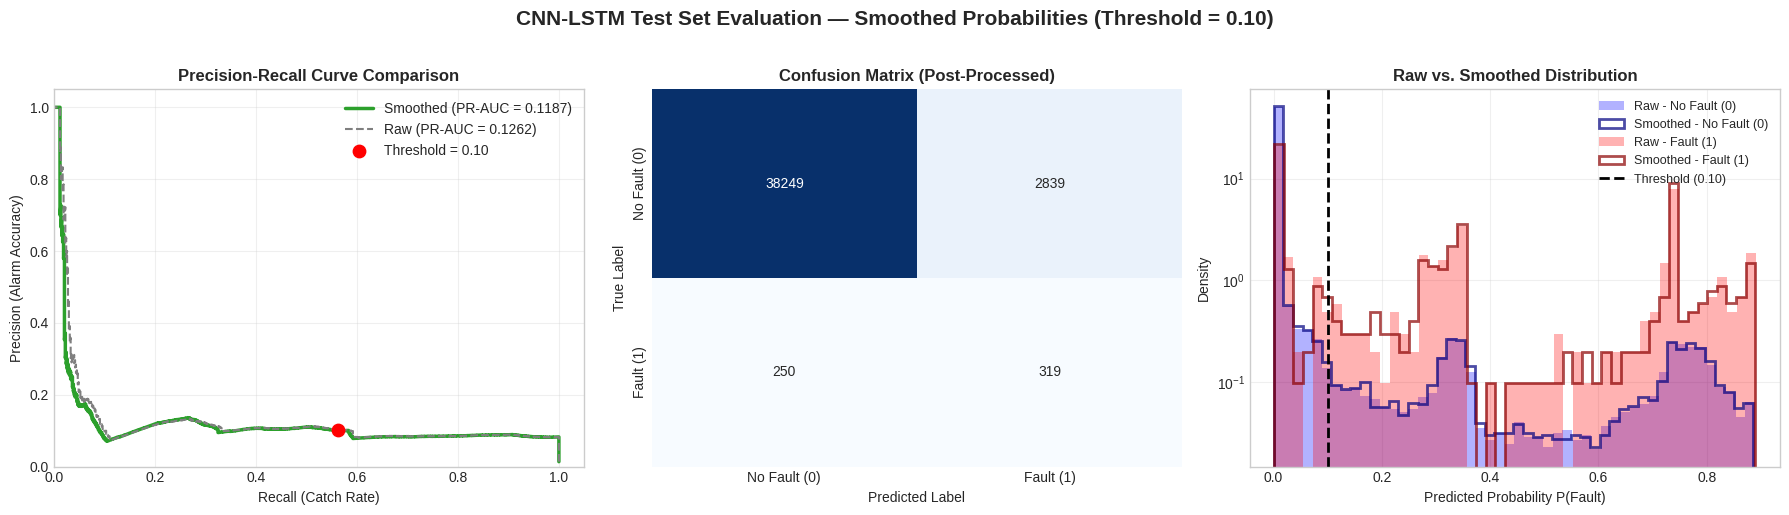

In [65]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.metrics import auc, confusion_matrix, precision_recall_curve

# Set style
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle(f"CNN-LSTM Test Set Evaluation — Smoothed Probabilities (Threshold = {FINAL_THRESH:.2f})",
             fontsize=15, fontweight="bold", y=1.02)

# -------------------------------------------------------------------------
# 1. Precision-Recall Curve (Smoothed vs. Raw)
# -------------------------------------------------------------------------
# Smoothed PR Curve
p_smooth, r_smooth, thresh_smooth = precision_recall_curve(y_test_seq, test_probs_smooth)
pr_auc_smooth = auc(r_smooth, p_smooth)

# Raw PR Curve
p_raw, r_raw, _ = precision_recall_curve(y_test_seq, test_probs_raw)
pr_auc_raw = auc(r_raw, p_raw)

axes[0].plot(r_smooth, p_smooth, color="#2ca02c", linewidth=2.5, label=f"Smoothed (PR-AUC = {pr_auc_smooth:.4f})")
axes[0].plot(r_raw, p_raw, color="#7f7f7f", linewidth=1.5, linestyle="--", label=f"Raw (PR-AUC = {pr_auc_raw:.4f})")

# Operating point on smoothed curve
idx = np.argmin(np.abs(thresh_smooth - FINAL_THRESH))
axes[0].scatter(r_smooth[idx], p_smooth[idx], color="red", s=80, zorder=5, label=f"Threshold = {FINAL_THRESH:.2f}")

axes[0].set_title("Precision-Recall Curve Comparison", fontweight="bold")
axes[0].set_xlabel("Recall (Catch Rate)")
axes[0].set_ylabel("Precision (Alarm Accuracy)")
axes[0].set_xlim([0.0, 1.05])
axes[0].set_ylim([0.0, 1.05])
axes[0].legend(loc="upper right")
axes[0].grid(True, alpha=0.3)

# -------------------------------------------------------------------------
# 2. Post-Processed Confusion Matrix
# -------------------------------------------------------------------------
cm = confusion_matrix(y_test_seq, test_preds)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=axes[1],
    cbar=False,
    xticklabels=["No Fault (0)", "Fault (1)"],
    yticklabels=["No Fault (0)", "Fault (1)"]
)
axes[1].set_title(f"Confusion Matrix (Post-Processed)", fontweight="bold")
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("True Label")

# -------------------------------------------------------------------------
# 3. Probability Distribution (Raw vs. Smoothed)
# -------------------------------------------------------------------------
axes[2].hist(test_probs_raw[y_test_seq == 0], bins=50, alpha=0.3, color="blue", label="Raw - No Fault (0)", density=True)
axes[2].hist(test_probs_smooth[y_test_seq == 0], bins=50, alpha=0.7, color="navy", histtype="step", linewidth=2, label="Smoothed - No Fault (0)", density=True)

axes[2].hist(test_probs_raw[y_test_seq == 1], bins=50, alpha=0.3, color="red", label="Raw - Fault (1)", density=True)
axes[2].hist(test_probs_smooth[y_test_seq == 1], bins=50, alpha=0.7, color="darkred", histtype="step", linewidth=2, label="Smoothed - Fault (1)", density=True)

axes[2].axvline(FINAL_THRESH, color="black", linestyle="--", linewidth=2, label=f"Threshold ({FINAL_THRESH:.2f})")

axes[2].set_title("Raw vs. Smoothed Distribution", fontweight="bold")
axes[2].set_xlabel("Predicted Probability P(Fault)")
axes[2].set_ylabel("Density")
axes[2].set_yscale("log")
axes[2].legend(loc="upper right", fontsize=9)
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()